In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Pengaturan tampilan visualisasi dan tabel
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

def load_datasets(nasabah_path: str, kredit_path: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Memuat dataset utama nasabah dan dataset kredit eksternal."""
    df_nasabah = pd.read_csv(nasabah_path)
    df_kredit = pd.read_csv(kredit_path)
    print("Dataset berhasil dimuat.")
    return df_nasabah, df_kredit

df_nasabah, df_kredit = load_datasets('nasabah_raw.csv', 'data_kredit_eksternal.csv')

Dataset berhasil dimuat.


## **a. Pemeriksaan Awal & Penghapusan Duplikat**

In [4]:
def inspect_and_deduplicate(df: pd.DataFrame) -> pd.DataFrame:
    """Memeriksa dimensi, tipe data, serta mengidentifikasi dan menghapus duplikat penuh."""
    print(f"1. Dimensi awal dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")
    print("Informasi tipe data tiap kolom:")
    df.info()

    # Identifikasi duplikat penuh
    jumlah_duplikat = df.duplicated().sum()
    print(f"\n2. Jumlah baris duplikat penuh: {jumlah_duplikat}")

    if jumlah_duplikat > 0:
        print("\nSampel baris yang terduplikasi:")
        display(df[df.duplicated(keep=False)].sort_values(by=df.columns[0]).head(6))

    # Hapus seluruh duplikat dan reset index
    df_clean = df.drop_duplicates(keep='first').reset_index(drop=True)
    print(f"\n3. Sisa baris data setelah penghapusan duplikat: {df_clean.shape[0]} baris")
    return df_clean

df_nasabah = inspect_and_deduplicate(df_nasabah)

1. Dimensi awal dataset: 1045 baris, 9 kolom

Informasi tipe data tiap kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB

2. Jumlah baris duplikat penuh: 45

Sampel baris yang terduplikasi:


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
59,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
1039,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
76,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
1011,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
96,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
1041,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0



3. Sisa baris data setelah penghapusan duplikat: 1000 baris


Analisis & Jawaban (a.3):


*    Sisa Baris Data: Jumlah sisa baris setelah tahap ini ditunjukkan secara otomatis oleh output df_clean.shape[0], yang secara matematis bernilai *Total Baris Awal - Jumlah Duplikat Penuh*.
*   Argumentasi Logis: Pemeriksaan .info() membantu mendeteksi kolom numerik yang mungkin terbaca sebagai object akibat karakter non-numerik. Penghapusan duplikat penuh wajib dilakukan di awal agar data ganda tidak mendistorsi perhitungan statistik (seperti median dan modus) serta mencegah kebocoran data (data leakage) apabila baris identik terpecah ke dalam training set dan testing set.





## **b. Penanganan Kesalahan Data**

In [5]:
def clean_data_errors(df: pd.DataFrame, min_age: int = 17, max_age: int = 100) -> pd.DataFrame:
    """Menstandarisasi teks Status_Pernikahan dan memvalidasi rentang logis kolom Usia."""
    df = df.copy()

    # 1. Pembersihan format teks pada Status_Pernikahan
    print("Nilai unik Status_Pernikahan SEBELUM pembersihan:")
    print(df['Status_Pernikahan'].value_counts(dropna=False))

    df['Status_Pernikahan'] = (
        df['Status_Pernikahan']
        .astype(str)
        .str.strip()
        .str.title()
        .replace({'Nan': np.nan, 'None': np.nan, '': np.nan})
    )

    print("\nNilai unik Status_Pernikahan SESUDAH pembersihan:")
    print(df['Status_Pernikahan'].value_counts(dropna=False))

    # 2. Pemeriksaan logis pada kolom Usia (17 - 100 tahun)
    invalid_age_mask = (df['Usia'] < min_age) | (df['Usia'] > max_age)
    print(f"\nJumlah anomali pada kolom Usia (<{min_age} atau >{max_age}): {invalid_age_mask.sum()}")

    df.loc[invalid_age_mask, 'Usia'] = np.nan
    return df

df_nasabah = clean_data_errors(df_nasabah, min_age=17, max_age=100)

Nilai unik Status_Pernikahan SEBELUM pembersihan:
Status_Pernikahan
Menikah      509
Single       342
Cerai         82
single        37
 MENIKAH      30
Name: count, dtype: int64

Nilai unik Status_Pernikahan SESUDAH pembersihan:
Status_Pernikahan
Menikah    539
Single     379
Cerai       82
Name: count, dtype: int64

Jumlah anomali pada kolom Usia (<17 atau >100): 35


Analisis & Jawaban (b.3):

* Standardisasi Kategori: Fungsi .str.strip() menghapus spasi berlebih di awal/akhir kata (misal " Menikah " menjadi "Menikah"), sedangkan .str.title() menyamakan kapitalisasi (misal "menikah" dan "MENIKAH" menjadi "Menikah"), sehingga algoritma tidak menganggapnya sebagai kategori yang berbeda.

* Mengapa koreksi kesalahan nilai pada Usia harus dilakukan sebelum menghitung mean atau median?
Nilai yang melanggar logika bisnis (seperti usia negatif -5, 0, atau 999 tahun) merupakan kesalahan entri data (noise), bukan representasi populasi nasabah yang sebenarnya. Jika mean dihitung sebelum nilai anomali diubah menjadi NaN, angka ekstrem tersebut akan menarik nilai rata-rata jauh dari pusat distribusi yang sesungguhnya. Meskipun median lebih tahan terhadap pencilan ekstrem, keberadaan banyak nilai tidak valid tetap menggeser titik tengah urutan data. Mengubah anomali menjadi NaN terlebih dahulu memastikan nilai imputasi yang dihitung benar-benar berasal dari distribusi nasabah yang valid.

## **c. Integrasi Data**

In [6]:
def merge_external_data(df_main: pd.DataFrame, df_ext: pd.DataFrame, key: str = 'ID_Pelanggan') -> pd.DataFrame:
    """Menggabungkan profil nasabah utama dengan data kredit eksternal menggunakan Left Join."""
    df_main = df_main.copy()
    df_ext = df_ext.copy()

    # Pastikan kunci penggabungan bersih dari spasi dan bertipe seragam
    df_main[key] = df_main[key].astype(str).str.strip()
    df_ext[key] = df_ext[key].astype(str).str.strip()

    # Pastikan tabel referensi eksternal tidak memiliki duplikat ID_Pelanggan
    df_ext = df_ext.drop_duplicates(subset=[key], keep='first')

    df_merged = pd.merge(df_main, df_ext, on=key, how='left')
    print(f"Dimensi dataset setelah Left Join: {df_merged.shape[0]} baris, {df_merged.shape[1]} kolom")
    return df_merged

df_merged = merge_external_data(df_nasabah, df_kredit, key='ID_Pelanggan')

Dimensi dataset setelah Left Join: 1000 baris, 11 kolom


Analisis (c.3):

* Penggunaan metode how='left' memastikan seluruh baris dari tabel profil nasabah utama (df_nasabah) tetap dipertahankan secara utuh (jumlah baris tidak berkurang), sementara atribut riwayat kredit dari data_kredit_eksternal.csv ditambahkan sebagai kolom baru. Jika ada nasabah utama yang belum memiliki catatan di biro kredit eksternal, kolom tambahannya akan otomatis terisi NaN untuk ditangani pada tahap berikutnya.

## **d. Penanganan Data yang Hilang (Missing Values)**

In [7]:
def handle_missing_values(df: pd.DataFrame) -> pd.DataFrame:
    """Menampilkan persentase missing values dan melakukan imputasi sesuai tipe fitur."""
    df = df.copy()

    # 1. Hitung dan tampilkan persentase missing values
    missing_pct = (df.isnull().sum() / len(df)) * 100
    missing_summary = pd.DataFrame({
        'Jumlah_Missing': df.isnull().sum(),
        'Persentase (%)': missing_pct.round(2)
    })
    print("1. Ringkasan Missing Values Sebelum Imputasi:")
    display(missing_summary[missing_summary['Jumlah_Missing'] > 0])

    # 2a. Imputasi kolom numerik kontinu dengan MEDIAN
    kontinu_cols = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn']
    for col in kontinu_cols:
        if col in df.columns:
            median_val = df[col].median()
            df[col] = df[col].fillna(median_val)

    # 2b. Imputasi kolom diskrit Jumlah_Kartu_Kredit dengan 0
    if 'Jumlah_Kartu_Kredit' in df.columns:
        df['Jumlah_Kartu_Kredit'] = df['Jumlah_Kartu_Kredit'].fillna(0)

    # 2c. Imputasi kolom kategorikal dengan MODUS (bersihkan spasi/kapitalisasi lebih dulu)
    kategorikal_cols = ['Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']
    for col in kategorikal_cols:
        if col in df.columns:
            # Rapikan format teks non-null sebelum mencari modus
            mask_notna = df[col].notna()
            df.loc[mask_notna, col] = df.loc[mask_notna, col].astype(str).str.strip()
            modus_val = df[col].mode()[0]
            df[col] = df[col].fillna(modus_val)

    # Imputasi pengaman jika masih ada kolom lain yang memiliki missing value
    for col in df.columns:
        if df[col].isnull().sum() > 0:
            if pd.api.types.is_numeric_dtype(df[col]):
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = df[col].fillna(df[col].mode()[0])

    # 3. Verifikasi akhir
    total_missing_akhir = df.isnull().sum().sum()
    print(f"\n3. Total sisa missing value pada seluruh dataset: {total_missing_akhir}")
    assert total_missing_akhir == 0, "Masih terdapat missing value pada dataset!"
    return df

df_clean = handle_missing_values(df_merged)

1. Ringkasan Missing Values Sebelum Imputasi:


,Jumlah_Missing,Persentase (%)
Usia,35,3.5
Pendapatan_Bulanan,60,6.0
Lama_Bekerja_Thn,40,4.0
Tingkat_Pendidikan,35,3.5
Pendapatan_Tahunan_Est,60,6.0
Pernah_Gagal_Bayar_Lain,150,15.0
Jumlah_Kartu_Kredit,150,15.0



3. Total sisa missing value pada seluruh dataset: 0


Analisis (d):

* Median untuk Variabel Kontinu: Data finansial dan demografis seperti Pendapatan_Bulanan umumnya menceng (skewed). Median dipilih karena lebih stabil (robust) terhadap nilai ekstrem dibandingkan mean.

* Nilai 0 untuk Variabel Diskrit: Nilai kosong pada Jumlah_Kartu_Kredit merepresentasikan ketiadaan kepemilikan produk kartu kredit dalam sistem eksternal, sehingga pengisian dengan 0 lebih akurat secara domain bisnis daripada nilai rata-rata.

* Modus untuk Variabel Kategorikal: Menjaga distribusi proporsi kategori mayoritas pada Tingkat_Pendidikan dan Pernah_Gagal_Bayar_Lain tanpa menciptakan kategori buatan baru.

## **e. Penanganan Pencilan (Outlier Handling)**

Statistik IQR untuk 'Pendapatan_Bulanan':
  Q1          : 10,192,000.00
  Q3          : 14,100,250.00
  IQR         : 3,908,250.00
  Batas Bawah : 4,329,625.00
  Batas Atas  : 19,962,625.00
  Jumlah outlier terdeteksi: 22 baris


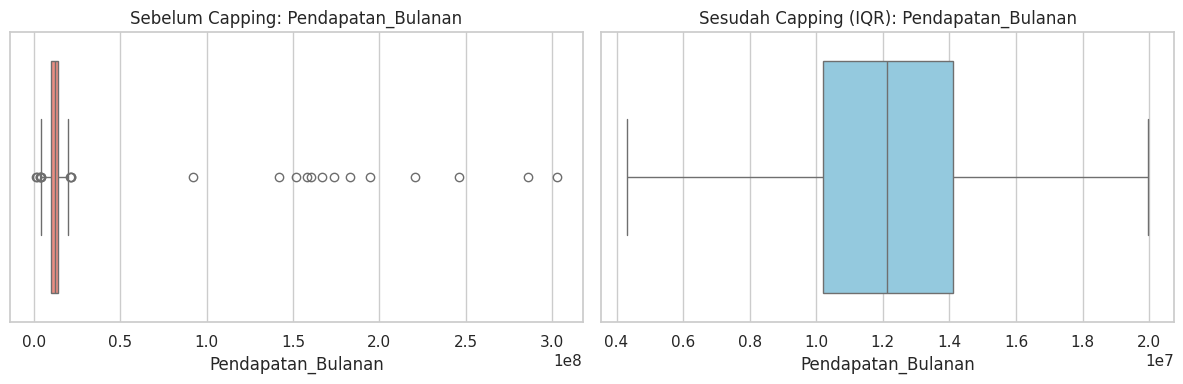

In [8]:
def handle_outliers_iqr(df: pd.DataFrame, col: str = 'Pendapatan_Bulanan') -> pd.DataFrame:
    """Memvisualisasikan boxplot serta melakukan Winsorizing (capping) berbasis metode IQR."""
    df = df.copy()

    # 2. Perhitungan Q1, Q3, IQR, Batas Bawah, dan Batas Atas
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    print(f"Statistik IQR untuk '{col}':")
    print(f"  Q1          : {Q1:,.2f}")
    print(f"  Q3          : {Q3:,.2f}")
    print(f"  IQR         : {IQR:,.2f}")
    print(f"  Batas Bawah : {batas_bawah:,.2f}")
    print(f"  Batas Atas  : {batas_atas:,.2f}")

    outliers_count = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()
    print(f"  Jumlah outlier terdeteksi: {outliers_count} baris")

    # 1 & 3. Visualisasi sebelum & sesudah Capping (Winsorizing)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x=df[col], ax=axes[0], color='salmon')
    axes[0].set_title(f'Sebelum Capping: {col}')

    # Terapkan pembatasan nilai ekstrem tanpa menghapus baris
    df[col] = df[col].clip(lower=batas_bawah, upper=batas_atas)

    sns.boxplot(x=df[col], ax=axes[1], color='skyblue')
    axes[1].set_title(f'Sesudah Capping (IQR): {col}')
    plt.tight_layout()
    plt.show()

    return df

df_clean = handle_outliers_iqr(df_clean, col='Pendapatan_Bulanan')

Analisis & Jawaban (e.4):

Konsekuensi negatif jika membuang baris (drop rows) yang mengandung outlier dibandingkan pembatasan (capping):

1. Hilangnya Informasi & Penurunan Ukuran Sampel: Membuang baris mengurangi volume data latih yang berharga, yang dapat menurunkan kemampuan generalisasi model.

2. Distorsi Distribusi Kelas Target (Class Imbalance): Dalam pemodelan risiko gagal bayar (Status_Default), nasabah dengan pendapatan ekstrem (sangat rendah maupun sangat tinggi) sering kali menyimpan sinyal risiko yang krusial. Menghapus baris-baris ini berisiko menghilangkan sampel kelas minoritas (nasabah gagal bayar) sehingga model menjadi bias.

3. Ketidaksesuaian dengan Data Produksi: Di dunia nyata, pengajuan kredit dari nasabah berpendapatan sangat tinggi atau rendah tetap akan masuk ke sistem. Teknik capping (Winsorizing) mempertahankan seluruh observasi nasabah sembari meredam skala ekstremnya agar tidak mendominasi bobot algoritma.

## **f. Pengkodean Data Kategorikal (Categorical Encoding)**

In [9]:
def encode_categorical_features(df: pd.DataFrame) -> pd.DataFrame:
    """Melakukan Ordinal Encoding, Binary Mapping, One-Hot Encoding, dan menghapus kolom non-fitur."""
    df = df.copy()

    # 1. Ordinal Encoding pada Tingkat_Pendidikan: SMA (1), Sarjana (2), Magister (3)
    pendidikan_mapping = {
        'Sma': 1, 'SMA': 1,
        'Sarjana': 2,
        'Magister': 3
    }
    df['Tingkat_Pendidikan_Encoded'] = df['Tingkat_Pendidikan'].str.strip().map(pendidikan_mapping)

    # 2. Binary Mapping (0 dan 1) pada Pernah_Gagal_Bayar_Lain
    binary_mapping = {
        'Tidak': 0, 'tidak': 0, 'No': 0, 'no': 0, '0': 0, 0: 0,
        'Ya': 1, 'ya': 1, 'Yes': 1, 'yes': 1, '1': 1, 1: 1
    }
    df['Pernah_Gagal_Bayar_Lain_Encoded'] = df['Pernah_Gagal_Bayar_Lain'].map(binary_mapping)

    # 3. One-Hot Encoding pada Status_Pernikahan dengan drop_first=True
    df = pd.get_dummies(
        df,
        columns=['Status_Pernikahan'],
        drop_first=True,
        dtype=int
    )

    # 4. Hapus kolom teks asli dan kolom identifier ID_Pelanggan
    cols_to_drop = ['ID_Pelanggan', 'Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']
    df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

    print("Kolom setelah Categorical Encoding:")
    print(df.columns.tolist())
    return df

df_encoded = encode_categorical_features(df_clean)

Kolom setelah Categorical Encoding:
['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Status_Default', 'Pendapatan_Tahunan_Est', 'Jumlah_Kartu_Kredit', 'Tingkat_Pendidikan_Encoded', 'Pernah_Gagal_Bayar_Lain_Encoded', 'Status_Pernikahan_Menikah', 'Status_Pernikahan_Single']


Analisis (f):

* Ordinal Encoding digunakan pada Tingkat_Pendidikan karena jenjang pendidikan memiliki hierarki atau tingkatan logis (SMA < Sarjana < Magister).

* Binary Mapping mengubah variabel dikotomis menjadi representasi numerik biner (0 dan 1).

* One-Hot Encoding dengan drop_first=True diterapkan pada Status_Pernikahan karena kategori pernikahan bersifat nominal (setara/tanpa urutan). Parameter drop_first=True membuang satu kolom referensi untuk menghindari dummy variable trap (multikolinearitas sempurna antarfitur prediktor).

* ID_Pelanggan dihapus karena bersifat unik untuk setiap individu dan tidak memiliki daya prediksi; mempertahankannya justru memicu overfitting.

## **g. Penskalaan Fitur (Feature Scaling)**

In [11]:
def scale_and_save_dataset(
    df: pd.DataFrame,
    target_col: str = 'Status_Default',
    output_filename: str = 'clean_nasabah_final.csv'
) -> tuple[pd.DataFrame, pd.Series, pd.DataFrame]:
    """Memisahkan X dan y, melakukan StandardScaler pada fitur numerik, dan menyimpan CSV akhir."""
    # 1. Pisahkan fitur prediktor (X) dan target (y)
    X = df.drop(columns=[target_col]).copy()
    y = df[target_col].copy()

    # Pilih 3 fitur numerik utama untuk perbandingan ringkasan statistik
    sample_num_cols = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn']

    print("3a. Ringkasan Statistik 3 Fitur Numerik SEBELUM Standarisasi:")
    display(X[sample_num_cols].describe().round(4))

    # 2. Transformasi Standardization (Z-score) pada seluruh variabel numerik prediktor
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    scaler = StandardScaler()
    X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

    print("\n3b. Ringkasan Statistik 3 Fitur Numerik SESUDAH Standarisasi:")
    display(X[sample_num_cols].describe().round(4))

    # Gabungkan kembali fitur yang telah bersih & terstandarisasi dengan target untuk disimpan
    df_final = pd.concat([X, y], axis=1)
    df_final.to_csv(output_filename, index=False)
    print(f"\nDataset akhir berhasil disimpan ke '{output_filename}' dengan dimensi {df_final.shape}.")

    return X, y, df_final

X, y, df_final = scale_and_save_dataset(
    df_encoded,
    target_col='Status_Default',
    output_filename='clean_nasabah_final.csv'
)

3a. Ringkasan Statistik 3 Fitur Numerik SEBELUM Standarisasi:


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1000.0000,1.000000e+03,1000.000
mean,40.0820,1.212750e+07,12.948
std,11.5801,3.062611e+06,6.690
min,20.0000,4.329625e+06,1.000
25%,30.0000,1.019200e+07,8.000
50%,41.0000,1.213200e+07,13.000
75%,50.0000,1.410025e+07,19.000
max,59.0000,1.996262e+07,24.000



3b. Ringkasan Statistik 3 Fitur Numerik SESUDAH Standarisasi:


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1000.0000,1000.0000,1000.0000
mean,-0.0000,0.0000,-0.0000
std,1.0005,1.0005,1.0005
min,-1.7350,-2.5474,-1.7868
25%,-0.8711,-0.6323,-0.7400
50%,0.0793,0.0015,0.0078
75%,0.8569,0.6445,0.9051
max,1.6345,2.5596,1.6528



Dataset akhir berhasil disimpan ke 'clean_nasabah_final.csv' dengan dimensi (1000, 11).


Analisis (g):

* Pemisahan $X$ dan $y$: Variabel target Status_Default dipisahkan terlebih dahulu agar label kelas (0 atau 1) tidak ikut mengalami transformasi Z-score.* Interpretasi .describe() Sebelum vs Sesudah: Sebelum penskalaan, Pendapatan_Bulanan memiliki skala jutaan sementara Usia berada pada puluhan; perbedaan skala ini dapat membuat algoritma berbasis jarak (seperti KNN, SVM) atau berbasis gradien (Logistic Regression, Neural Networks) didominasi oleh variabel berskala besar. Setelah StandardScaler ($z = \frac{x - \mu}{\sigma}$), ketiga fitur numerik memiliki nilai mean sebesar 0.0000 dan std sebesar 1.0000, sehingga seluruh fitur berada pada skala yang setara dan siap digunakan untuk pelatihan model Machine Learning.